# COAST tutorial 1: control and injured mouse kidney

COAST orders cross-sections of a repeated tissue structure along one continuous axis, the **pseudostructure**
coordinate, using expression alone, and then asks how genes change along it. This tutorial runs COAST on the control and acute kidney injury (AKI) mouse data of the paper: Visium HD
sections of two control mouse kidneys (Ctrl1A2, Ctrl1A4) and two kidneys after ischaemia-reperfusion injury
(IR2A2, IR2A4). Every unit is one segmented tubule cross-section. All four sections are fitted together, so control
and injured tubules share one pseudostructure coordinate; this is the control + AKI fit of the paper (Fig. 3, top
row; Fig. 6).

The second tutorial, `human_vs_mouse.ipynb`, does the same for the two control mice and a healthy human kidney.

**Input**, per section:

- the Space Ranger output of the Visium HD run at 2 µm (`binned_outputs/square_002um/`: the bin x gene count
  matrix, the bin positions and the scale factors), and
- the segmentation of the H&E image as a GeoJSON file (here a QuPath export; one polygon per tubule cross-section,
  with its segmentation class), in the pixel frame of the full-resolution image.

The data will be released with the paper and are not part of this repository. Each section's folder is expected at
`data/<section>/square_002um/` and its segmentation at `data/<section>.geojson`. Some outputs are left out below.

In [1]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import spearmanr

import coast

sc.settings.verbosity = 0
DATA = Path("data")
SAMPLES = {"Ctrl1A2": "Control", "Ctrl1A4": "Control", "IR2A2": "AKI", "IR2A4": "AKI"}
COLORS = {"Control": "#2F6DB5", "AKI": "#D9692B"}

# broad identities of the nephron and their markers, for the doublet calls; neighbours along the nephron may meet
# inside one polygon
regions = {
    "Proximal_Tubule": ["Lrp2", "Cubn", "Slc5a2", "Slc5a12", "Slc13a3", "Slc22a6", "Slc34a1"],
    "Thin_Limb": ["Aqp1", "Cldn10", "Cryab", "Tacstd2", "Cldn1"],
    "TAL": ["Slc12a1", "Umod", "Cldn16", "Egf", "Casr"],
    "DCT": ["Slc12a3", "Trpm6", "Cnnm2", "Pvalb"],
    "CNT_CD": ["Calb1", "Aqp2", "Aqp3", "Scnn1b", "Slc4a1", "Slc26a4"],
}
adjacency = {"Proximal_Tubule": ["Thin_Limb"], "Thin_Limb": ["Proximal_Tubule", "TAL"], "TAL": ["Thin_Limb", "DCT"],
             "DCT": ["TAL", "CNT_CD"], "CNT_CD": ["DCT"]}
region_markers = sorted({g for genes in regions.values() for g in genes})

## 1. From bins to units

`io.read_visium_hd` reads the in-tissue bins with their positions in image pixels, and `io.read_segmentation` the
polygons. `pp.bins_to_units` gives every bin to the polygon that covers its centre and sums the bins of each polygon:
one **unit** per polygon, raw counts, with `n_spots` (its bins), `bin_coverage` (bins x bin area / polygon area) and
the polygon's size and shape. It also writes each bin's unit into `bins.obs['unit']`. Only the marker-gene counts of
the assigned bins are kept; the doublet calls below look inside units with them. This takes about a minute per section.

In [2]:
units, bins, polygons = {}, [], []
for sample in SAMPLES:
    section = coast.io.read_visium_hd(DATA / sample / "square_002um")
    segmentation = coast.io.read_segmentation(DATA / f"{sample}.geojson")
    units[sample] = coast.pp.bins_to_units(section, segmentation, sample)
    inside = section.obs["unit"].notna().to_numpy()
    bins.append(section[inside, [g for g in region_markers if g in section.var_names]].copy())
    polygons.append(pd.Series(segmentation["geometry"].to_numpy(), index=units[sample].obs_names))
    del section
bins, polygons = ad.concat(bins, join="outer", fill_value=0), pd.concat(polygons)
units["Ctrl1A2"].obs.iloc[:3, :9]

,sample,unit_id,feature_index,seg_class,seg_score,n_spots,polygon_area_px,bin_coverage,area_pixels
Ctrl1A2_unit_0,Ctrl1A2,unit_0,0,tubule_proximal,0.9904,0,10085.0,0.0,10085.0
Ctrl1A2_unit_1,Ctrl1A2,unit_1,1,tubule_proximal,0.9853,0,11814.5,0.0,11814.5
Ctrl1A2_unit_2,Ctrl1A2,unit_2,2,tubule_proximal,0.9908,0,9414.0,0.0,9414.0


In [3]:
adata = ad.concat(units, merge="same")
adata.obs["sample"] = pd.Categorical(adata.obs["sample"], categories=list(SAMPLES))
adata.obs["condition"] = adata.obs["sample"].map(SAMPLES).astype("category")
print(f"{adata.n_vars} genes, {adata.n_obs} units")

19059 genes, 64080 units


## 2. Quality control

Three steps, as in the paper:

1. **Hard floors.** At least 500 counts, and bins covering at least 90% of the polygon (`bin_coverage`). Units
   clipped by the edge of the capture area fall below it.
2. **Doublets.** `pp.doublets` flags units that hold two structures: two incompatible identities in the whole unit
   (tier 1) or in two places of it (2, a permutation test on its bins), large and not convex (3), or two pieces
   joined by a neck (4). Tiers 2-4 are discarded, as in the paper; glomeruli, which hold several cell types, are
   never flagged.
3. **Outliers.** Units whose log counts, log counts per bin, or genes-vs-counts residual is more than 3 robust SDs
   from the median of their section x segmentation class.

In [4]:
floors = coast.pp.filter_units(adata, min_counts=500, min_coverage=0.9, n_mads=None)
coast.pp.doublets(floors, bins[bins.obs["unit"].isin(floors.obs_names)], polygons[floors.obs_names].tolist(), regions,
                  adjacency, class_key="seg_class", exempt=("glomerulus",), discard=("2", "3", "4"))
outliers = coast.pp.filter_units(floors, min_counts=500, min_coverage=0.9, n_mads=3, groupby=["sample", "seg_class"],
                                 bins_key="n_spots")
doublet = floors.obs["doublet"].to_numpy(bool)
qc = floors[floors.obs_names.isin(outliers.obs_names) & ~doublet].copy()
pd.DataFrame({"units": adata.obs["sample"].value_counts(sort=False),
              "hard floors": floors.obs["sample"].value_counts(sort=False),
              "doublets": floors.obs.loc[doublet, "sample"].value_counts(sort=False),
              "after QC": qc.obs["sample"].value_counts(sort=False)})

,units,hard floors,doublets,after QC
sample,,,,
Ctrl1A2,13587,8924,856,7838
Ctrl1A4,14656,8172,650,7212
IR2A2,18274,11777,797,10609
IR2A4,17563,12101,723,10951


## 3. Integrate and label clusters

`filter_genes` keeps genes detected in at least 5% of units (plus the marker genes in `keep`), and `normalize`
keeps the raw counts in `layers['counts']` and log-normalises `X`. `integrate` selects variable genes, runs PCA
and removes section effects with Harmony (`obsm['X_harmony']`). `group_key="condition"` keeps only genes that are
variable in both conditions, so the correction never sees the genes that differ
between them, which are the genes compared later.

Each Leiden cluster takes the name of its best-scoring marker panel. `label_clusters` returns the cluster x panel
score table with each cluster's margin over the runner-up; check it before trusting a label. The cluster that wins
the ATL panel is not ascending thin limb (it was checked on the H&E), so it is dropped with the non-tubule
classes.

In [5]:
panels = {
    "Podocyte": ["Nphs1", "Nphs2", "Podxl"],
    "PT-S1": ["Slc5a2", "Slc5a12", "Gatm"],
    "PT-S2": ["Slc22a6", "Slc13a3", "Cyp2e1"],
    "PT-S3": ["Slc7a13", "Slc22a7", "Cyp7b1"],
    "DTL1": ["Corin", "Uncx", "Slc14a2"],
    "DTL2": ["Fst", "Cdh13", "Stk32a"],
    "DTL3": ["Nr2e3", "Dmkn"],
    "ATL": ["Clcnka", "Sptssb", "Akr1b3"],
    "mTAL": ["Slc12a1", "Umod", "Cldn10", "Ptger3"],
    "cTAL": ["Slc12a1", "Umod", "Cldn16", "Kcnj10"],
    "Macula-densa": ["Nos1", "Ptgs2", "Pappa2"],
    "DCT1": ["Slc12a3", "Pvalb", "Trpm6", "Egf"],
    "DCT2": ["Slc12a3", "Trpv5", "Slc8a1", "S100g"],
    "CNT": ["Calb1", "Slc8a1", "Aqp2", "Rhcg"],
    "CCD": ["Aqp2", "Aqp3", "Kit"],
    "OMCD": ["Aqp2", "Atp6v0d2", "Rhcg"],
    "IMCD": ["Aqp2", "Aqp4", "Slc14a2", "Wnt7b"],
    "Vessel": ["Pecam1", "Cdh5", "Kdr", "Emcn", "Flt1", "Egfl7"],
    "Stroma": ["Col1a1", "Col3a1", "Col1a2", "Dcn", "Pdgfrb", "Mgp"],
    "SmoothMuscle": ["Acta2", "Myh11", "Tagln", "Rgs5", "Pdgfra"],
    "Immune": ["Ptprc", "C1qa", "C1qb", "Cd52", "Lyz2", "Cd74"],
}
early = ["Cyp2e1", "Gatm", "Slc13a3", "Slc22a6", "Slc5a12", "Slc5a2"]
late = ["Aqp2", "Aqp4", "Atp6v0d2", "Rhcg", "Slc14a2", "Wnt7b"]
# genes kept by the gene filter even when sparse: panel and anchor genes, other segment markers, injury markers
keep = sorted({g for genes in panels.values() for g in genes} | set(early) | set(late) | {
    "Aqp6", "Atp6v1b1", "Atp6v1g3", "Ccdc3", "Foxi1", "Igfbp2", "Insrr", "Lrp2", "Scnn1g", "Shd", "Slc1a1",
    "Slc22a5", "Slc26a4", "Slc26a7", "Slc34a1", "Slc3a1", "Slc4a1", "Slc4a4", "Slc4a9", "Slc5a1", "Sycn", "Tmem86a",
    "Vcam1", "Dcdc2a", "Krt20", "Sox9", "Havcr1", "Lcn2", "Spp1", "Cubn", "Aqp1", "Cldn10", "Cryab", "Tacstd2",
    "Cldn1", "Cldn16", "Egf", "Casr", "Cnnm2", "Calb1", "Scnn1b"})

In [6]:
def integrate(units):
    a = coast.pp.filter_genes(units, keep=keep)
    coast.pp.normalize(a)
    coast.pp.integrate(a, batch_key="sample", group_key="condition")
    sc.tl.leiden(a, resolution=2, flavor="igraph", n_iterations=2, random_state=0)
    return a

pass1 = integrate(qc)
scores = coast.tl.label_clusters(pass1, panels)

In [7]:
scores.round(2)

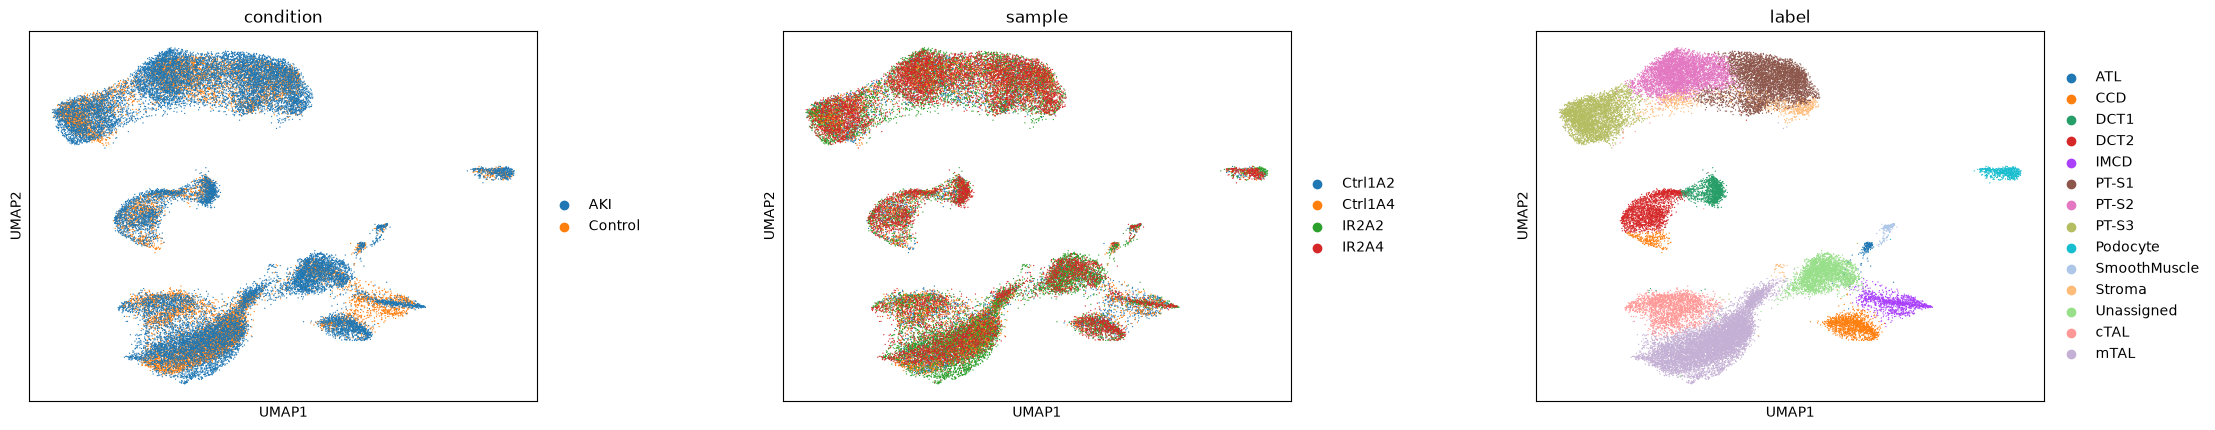

In [8]:
sc.pl.umap(pass1, color=["condition", "sample", "label"], wspace=0.35)

Keep the nephron tubule segments and integrate again from the raw counts. The second pass builds the
embedding from the tubules alone, which gives a cleaner axis.

In [9]:
nephron = ["PT-S1", "PT-S2", "PT-S3", "DTL1", "DTL2", "DTL3", "mTAL", "cTAL", "Macula-densa",
           "DCT1", "DCT2", "CNT", "CCD", "OMCD", "IMCD"]
adata = integrate(qc[pass1.obs_names[pass1.obs["label"].isin(nephron)]].copy())
adata.obs["label"] = pass1.obs.loc[adata.obs_names, "label"].astype(str).astype("category")
adata.obs["label"].value_counts()

label
mTAL     9392
PT-S1    5340
PT-S2    4809
PT-S3    3961
cTAL     2341
DCT2     1951
CCD      1708
DCT1     1270
IMCD     1156
Name: count, dtype: int64

## 4. The pseudostructure coordinate

`pseudostructure` fits an elastic principal curve (ElPiGraph; 50 nodes) through the 50 Harmony dimensions and
projects every unit onto it. Units beyond either end are placed on the continuation of the end edge instead of
being piled onto the end node. Marker genes only set the direction: 0 at the early markers (proximal tubule), 1 at
the late ones (collecting duct). Cluster labels never enter the fit.

For display the fine labels are grouped into the paper's segments: PT S1-S3, thin limb (TL), ascending limb (AL),
distal convoluted tubule (DCT), connecting tubule (CNT) and collecting duct (CD).

In [10]:
coast.tl.pseudostructure(adata, early_genes=early, late_genes=late)

SEGMENTS = {"PT-S1": "PTS1", "PT-S2": "PTS2", "PT-S3": "PTS3", "DTL1": "TL", "DTL2": "TL", "DTL3": "TL",
            "mTAL": "AL", "cTAL": "AL", "Macula-densa": "AL", "DCT1": "DCT", "DCT2": "DCT", "CNT": "CNT",
            "CCD": "CD", "OMCD": "CD", "IMCD": "CD"}
SEGMENT_COLORS = {"PTS1": "#4C8DC9", "PTS2": "#5BA55B", "PTS3": "#C9A46B", "TL": "#999999", "AL": "#EE8A2E",
                  "DCT": "#E06AA6", "CNT": "#6FC2B4", "CD": "#3F5FA8"}
order = [s for s in SEGMENT_COLORS if s in set(adata.obs["label"].map(SEGMENTS))]
adata.obs["segment"] = pd.Categorical(adata.obs["label"].map(SEGMENTS), categories=order)
adata.uns["segment_colors"] = [SEGMENT_COLORS[s] for s in order]

`pl.curve` draws the units and the curve. With `basis="X_umap"` the units are drawn on the UMAP, and each
curve node at the median UMAP position of the units nearest to it in the Harmony space. This only places the curve
for display; the fit is the same. Stars mark the two ends of the coordinate. (Paper Fig. 3a.)

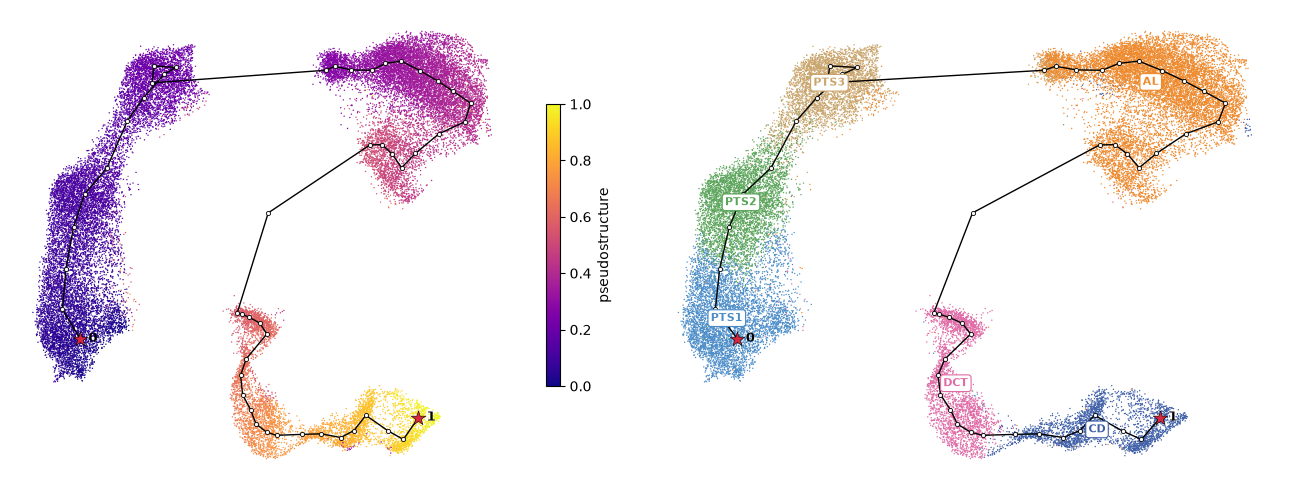

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
coast.pl.curve(adata, color="pseudostructure", basis="X_umap", cmap="plasma", s=1, ax=axes[0])
coast.pl.curve(adata, color="segment", basis="X_umap", legend="on data", s=1, ax=axes[1])
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()

**Do the segments come out in order?** Labels never enter the fit, so they can check it. Per
condition: one marker per segment along the coordinate (`pl.markers_along`; the
band on top gives each stretch the segment holding the largest share of its units), and the distribution of each
segment along it (`pl.labels_along`). ρ is the Spearman correlation, per section, between a unit's coordinate and
its segment's place along the nephron. (Paper Fig. 3b, c.)

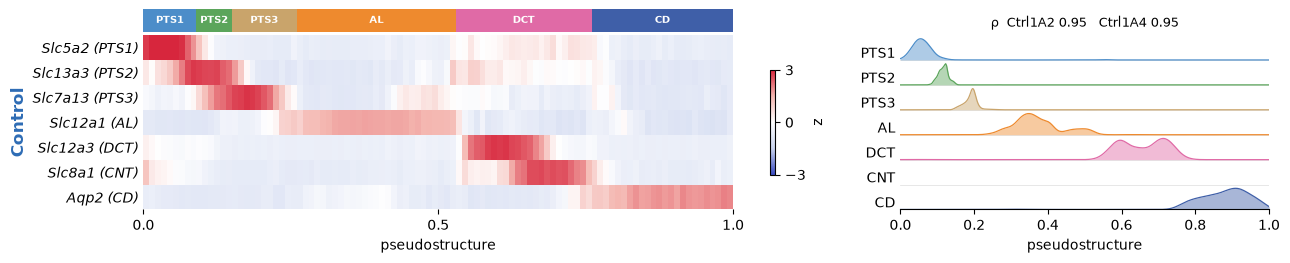

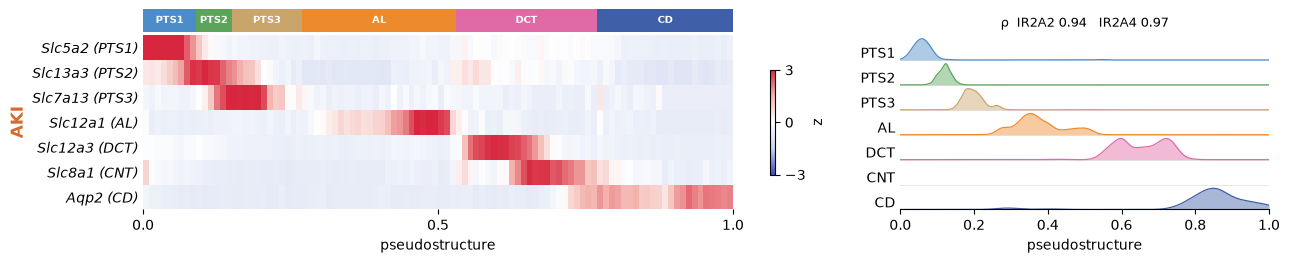

In [12]:
markers = {"Slc5a2": "PTS1", "Slc13a3": "PTS2", "Slc7a13": "PTS3", "Slc12a1": "AL", "Slc12a3": "DCT",
           "Slc8a1": "CNT", "Aqp2": "CD"}
rank = adata.obs["segment"].cat.codes
rho = {s: spearmanr(adata.obs.loc[m, "pseudostructure"], rank[m]).statistic
       for s in SAMPLES for m in [(adata.obs["sample"] == s).to_numpy()]}

for group in ["Control", "AKI"]:
    part = adata[adata.obs["condition"] == group]
    fig, axes = plt.subplots(1, 2, figsize=(13, 2.8), width_ratios=[2, 1])
    coast.pl.markers_along(part, markers, "segment", ax=axes[0])
    coast.pl.labels_along(part, "segment", order=list(markers.values()), ax=axes[1])
    axes[0].set_ylabel(group, color=COLORS[group], fontsize=12, weight="bold")
    axes[1].set_title("ρ  " + "   ".join(f"{s} {rho[s]:.2f}" for s in SAMPLES if SAMPLES[s] == group), fontsize=9)
    plt.tight_layout()

The same check on fitted curves. `tl.fit_curves` gives each gene's fitted expression along the coordinate
(log2 counts per 10k; a negative-binomial GAM), and `pl.heatmap` z-scores every gene. By default it orders the rows
by where the genes peak; here `order` keeps the markers in nephron order in both panels, so their peaks should run
down the diagonal. The whole nephron has sharp segment boundaries, so the spline gets more knots (`k=12`) than the
default.

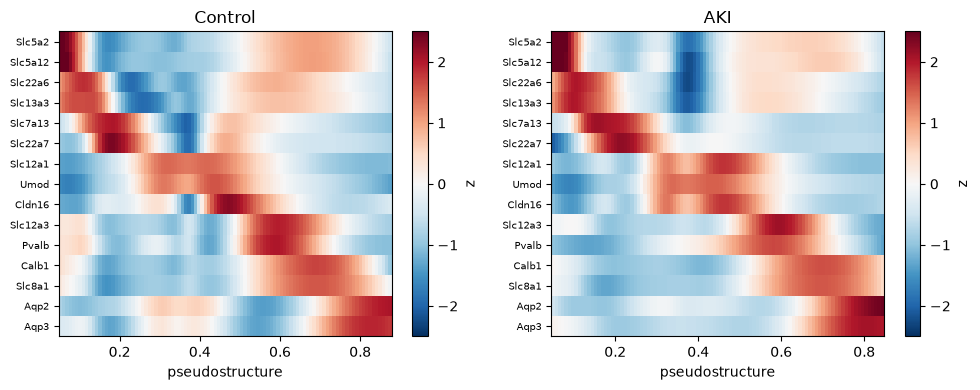

In [13]:
nephron_markers = [g for g in ["Slc5a2", "Slc5a12", "Slc22a6", "Slc13a3", "Slc7a13", "Slc22a7", "Slc12a1", "Umod",
                                 "Cldn16", "Slc12a3", "Pvalb", "Calb1", "Slc8a1", "Aqp2", "Aqp3"] if g in adata.var_names]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, group in zip(axes, ["Control", "AKI"]):
    marker_curves = coast.tl.fit_curves(adata[adata.obs["condition"] == group], nephron_markers, k=12)
    coast.pl.heatmap(marker_curves, order=nephron_markers, ax=ax)
    ax.set_title(group)
plt.tight_layout()

## 5. Genes along the proximal tubule

From here on, the proximal tubule (PT S1-S3). Its coordinate is re-expressed as a quantile of the
control PT units: control units are spread evenly over 0-1, and AKI
units are placed through the control distribution, so equal stretches hold equal numbers of control
units. Counts come from all genes (`qc`), with the library size of the non-mitochondrial genes.

`pl.genes` shows the fitted curve of each gene (`tl.fit_curves`: a negative-binomial GAM, one penalised spline
per section) and binned data (points).

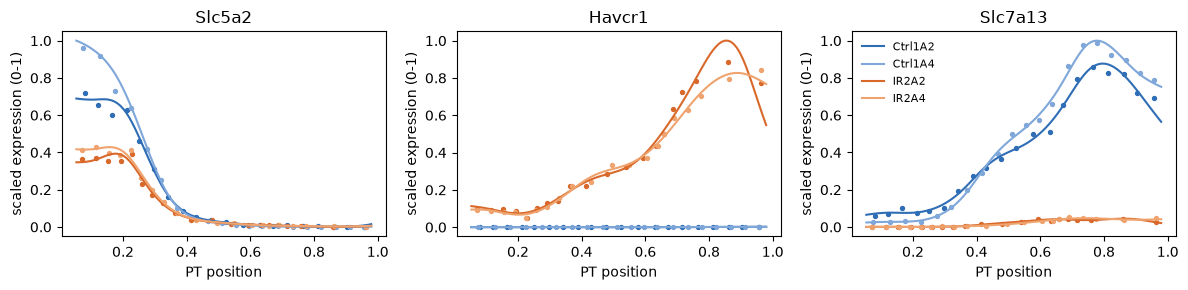

In [14]:
pt = qc[adata.obs_names[adata.obs["label"].isin(["PT-S1", "PT-S2", "PT-S3"])]].copy()
pt.obs[["label", "pseudostructure"]] = adata.obs.loc[pt.obs_names, ["label", "pseudostructure"]]
pt.layers["counts"] = pt.X
mt = pt.var_names.str.startswith("mt-")
pt.obs["library"] = np.asarray(pt.X[:, ~mt].sum(axis=1)).ravel()

ref = (pt.obs["condition"] == "Control").to_numpy()
t = pt.obs["pseudostructure"].to_numpy()
x = np.empty(pt.n_obs)
x[ref] = (pd.Series(t[ref]).rank().to_numpy() - 0.5) / ref.sum()
x[~ref] = np.interp(t[~ref], np.sort(t[ref]), np.sort(x[ref]))
pt.obs["PT position"] = x
pt.obs["sample"] = pd.Categorical(pt.obs["sample"], categories=list(SAMPLES))
pt.uns["sample_colors"] = ["#2F6DB5", "#7FA7D9", "#D9692B", "#EFA36E"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
coast.pl.genes(pt, ["Slc5a2", "Havcr1", "Slc7a13"], x="PT position", sample_key="sample", library="library", axes=axes)
plt.tight_layout()

`sample_key` can be any obs column: one line per condition pools its sections.

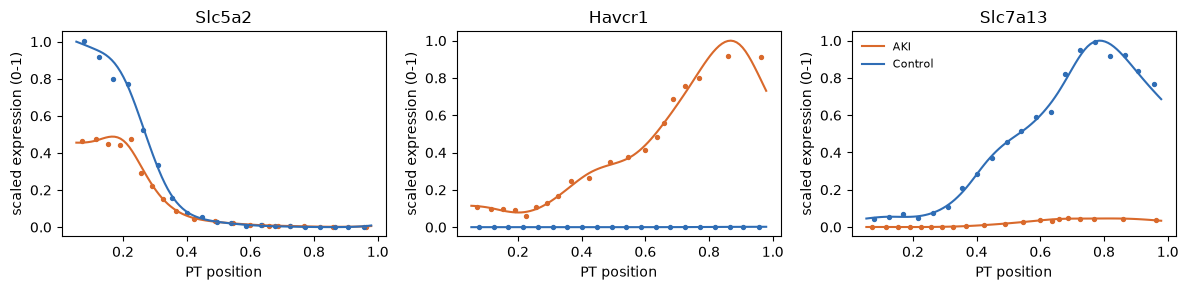

In [15]:
pt.uns["condition_colors"] = [COLORS[g] for g in pt.obs["condition"].cat.categories]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
coast.pl.genes(pt, ["Slc5a2", "Havcr1", "Slc7a13"], x="PT position", sample_key="condition", library="library", axes=axes)
plt.tight_layout()

## 6. Which genes change along the proximal tubule

`tl.test_genes` fits a negative-binomial GLM per gene to raw counts, with a log(library) offset and a cubic spline
in the coordinate, and compares it with an intercept-only model. Units of one structure are not independent, so
genes are called against a **decoy**: the same fits with the coordinate shuffled. `significant` keeps genes above
the first threshold where decoy calls / real calls <= 5%. With thousands of units tiny shifts are significant, so
also require an effect size: `log2_range` is the size of the fitted pattern in log2 units.

Test every section on its own and keep genes called in both sections of a condition. To keep this run short only the
integration genes are tested; pass `genes=None` to test all.

In [16]:
tested = adata.var_names[adata.var["coast_feature"]]
groups = {g: [s for s in SAMPLES if SAMPLES[s] == g] for g in ["Control", "AKI"]}


def replicated(results, members):
    return pd.concat({s: results[s]["significant"] & (results[s]["log2_range"] >= 1) for s in members},
                     axis=1).all(axis=1)


positional = {s: coast.tl.test_genes(pt[pt.obs["sample"] == s], x="PT position", genes=tested, library="library",
                                     n_jobs=-1) for s in SAMPLES}
calls = pd.DataFrame({g: replicated(positional, members) for g, members in groups.items()})
pd.crosstab(calls["Control"], calls["AKI"])

AKI,False,True
Control,,
False,328,210
True,269,488


**Beyond clusters.** With `groupby`, the null model has one mean per cluster (here PT-S1/S2/S3), so a gene is
called only when the curve explains it better than steps between segments.

In [17]:
beyond = {s: coast.tl.test_genes(pt[pt.obs["sample"] == s], x="PT position", groupby="label", genes=tested,
                                 library="library", n_jobs=-1) for s in SAMPLES}
pd.DataFrame({g: replicated(beyond, members) for g, members in groups.items()}).sum().rename("genes")

Control    443
AKI        448
Name: genes, dtype: int64

The genes called in control, fitted in each condition and drawn with `pl.heatmap`. Both panels keep the control row
order (genes by where they peak in control), so a gene whose peak moves in AKI falls off the diagonal.

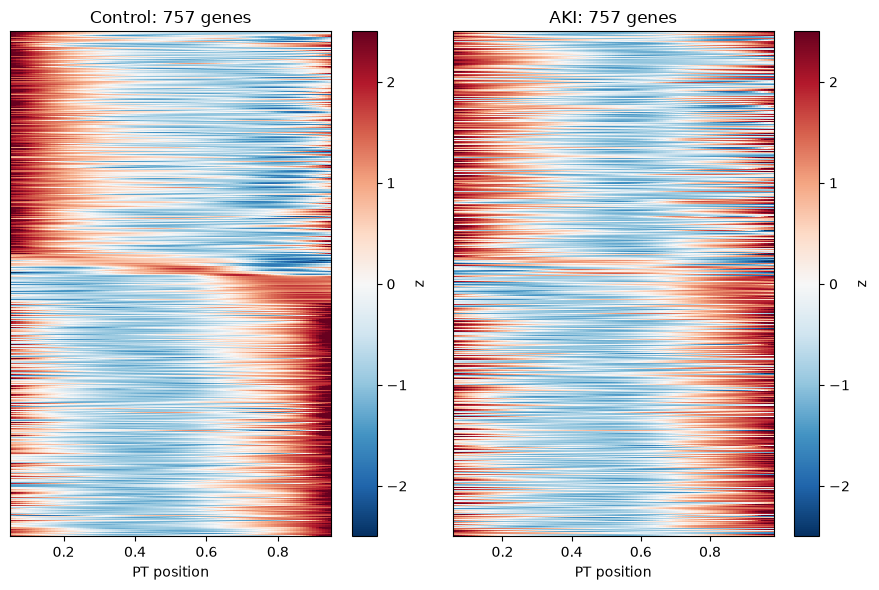

In [18]:
called = calls.index[calls["Control"]]
fitted = {g: coast.tl.fit_curves(pt[pt.obs["condition"] == g], called, x="PT position", library="library", n_jobs=-1)
          for g in groups}
order = fitted["Control"].dropna(how="all").idxmax(axis=1).sort_values(kind="stable").index
fig, axes = plt.subplots(1, 2, figsize=(9, 6))
for ax, (g, group_curves) in zip(axes, fitted.items()):
    coast.pl.heatmap(group_curves, order=order, ax=ax)
    ax.set_title(f"{g}: {len(order)} genes")
plt.tight_layout()

## 7. Genes that differ in level between control and AKI

`tl.compare_groups` asks whether a gene is higher or lower in AKI, along the whole PT or in one stretch of it. It
fits one curve per section and takes the log2 gap between the two groups' mean curves at every position,
re-referenced to the typical gene so that a global difference in depth cancels. A gene is selected when every
AKI x control pair of sections reproduces the gap, and the gap is at least twice the one between mixed splits
(each side one control and one AKI section, so the real difference cancels).

Genes, here and in the next section, as in the paper: detected in at least 10% of PT units in both sections of either condition, not
mitochondrial, and not more than twice as high in a neighbouring segment (AL, DCT, CD) as in the PT, in either
condition (their PT signal could come from the neighbour). This takes a few minutes.

In [19]:
counts = pt.X.tocsc()
detected = {s: np.asarray((counts[(pt.obs["sample"] == s).to_numpy()] > 0).mean(axis=0)).ravel() for s in SAMPLES}
universe = np.any([np.all([detected[s] >= 0.1 for s in g], axis=0) for g in groups.values()], axis=0) & ~mt

neighbour = {"mTAL": "AL", "cTAL": "AL", "Macula-densa": "AL", "DCT1": "DCT", "DCT2": "DCT",
             "CCD": "CD", "OMCD": "CD", "IMCD": "CD"}
lib = np.asarray(qc.X[:, ~qc.var_names.str.startswith("mt-")].sum(axis=1)).ravel()
labels = adata.obs["label"].reindex(qc.obs_names).astype(str).to_numpy()
ok = np.ones(qc.n_vars, bool)
for g, members in groups.items():
    in_group = qc.obs["sample"].isin(members).to_numpy()
    rate = lambda m: np.asarray(qc.X[m].sum(axis=0)).ravel() / lib[m].sum()
    pt_rate = rate(in_group & np.isin(labels, ["PT-S1", "PT-S2", "PT-S3"]))
    nb_rate = np.max([rate(in_group & np.isin(labels, [k for k, v in neighbour.items() if v == n]))
                      for n in ("AL", "DCT", "CD")], axis=0)
    ok &= nb_rate <= 2 * np.maximum(pt_rate, 1e-12)
genes = pt.var_names[universe & ok]
print(len(genes), "genes")

level, gap = coast.tl.compare_groups(pt, "condition", case="AKI", reference="Control", x="PT position", genes=genes,
                                     library="library", n_jobs=-1)
level = level[level["selected"]].sort_values("rms", ascending=False)
level["direction"].value_counts()

5496 genes


direction
down         1912
up           1852
crossover     126
Name: count, dtype: int64

The strongest gene of each direction (`up`: higher in AKI; `crossover`: higher in one stretch, lower in
another).

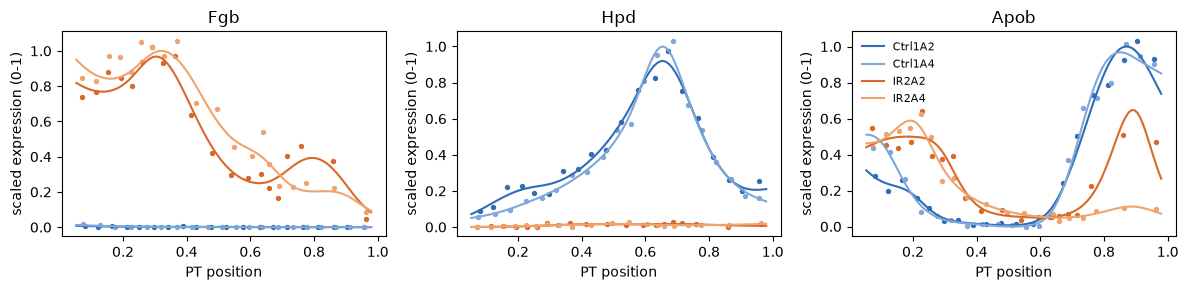

In [20]:
top = level.groupby("direction").head(1).index
fig, axes = plt.subplots(1, len(top), figsize=(4 * len(top), 3), squeeze=False)
coast.pl.genes(pt, top, x="PT position", sample_key="sample", library="library", axes=axes[0])
plt.tight_layout()

In [21]:
level.groupby("direction").head(10)

## 8. Clustering genes by how their shape changes

Which genes change **shape** along the PT between control and AKI, and in which
ways? `tl.shape_clusters` compares shapes only: each section's curve is centred and scaled to unit variance, so
differences in level or amplitude  do not count.

1. **Genes.** The genes of the previous section.
2. **Curves.** `fit_curves` on all of them, one curve per section (this takes a few minutes).
3. **Changed genes.** A gene is eligible when it changes at least √2-fold (0.5 log2) along the PT in every section
   of control or of AKI. Its difference curve is the mean AKI shape minus the mean
   control shape. It changes when that curve's RMS is at least 0.5 (z units; 2 is a full reversal) and both mixed
   splits (each side one control and one AKI section, so the real difference cancels) give at most half
   of it.
4. **Clusters.** The changed genes' difference curves are cut into four Ward clusters.

In [22]:
curves = coast.tl.fit_curves(pt, genes, x="PT position", sample_key="sample", library="library", n_jobs=-1)
table, shapes = coast.tl.shape_clusters(curves, reference=groups["Control"], case=groups["AKI"])
print(f"{len(table)} eligible, {table['changed'].sum()} change shape")
table[table["changed"]]["cluster"].value_counts().sort_index()

1633 eligible, 641 change shape


cluster
1     62
2    137
3    199
4    243
Name: count, dtype: int64

Each panel is one cluster: the mean shape of its genes in each section (thin) and each
condition (thick), titled with its size and the two genes that change most.
(Paper Fig. 6f.)

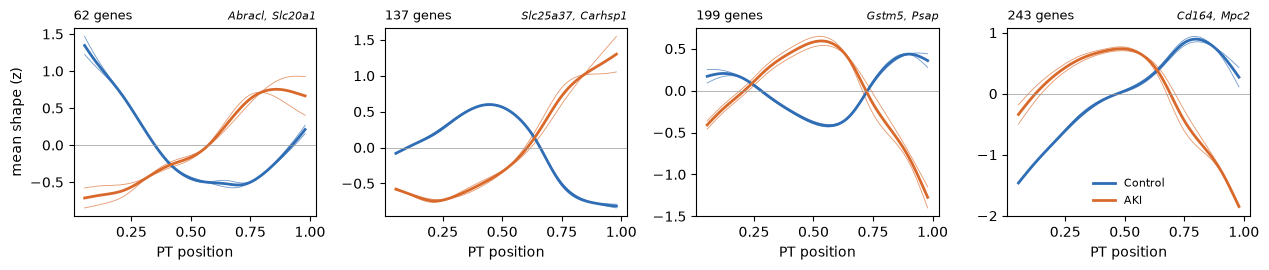

In [23]:
coast.pl.shape_clusters(table, shapes, groups=SAMPLES, colors=COLORS)
plt.tight_layout()

In [24]:
table[table["changed"]].sort_values(["cluster", "rms"], ascending=[True, False]).groupby("cluster").head(10)